In [604]:
from time import time

import matplotlib.pyplot as plt
import numpy as np
from numpy import cos, sin, sqrt
from numpy.linalg import cholesky, inv, norm
from scipy.linalg import sqrtm

In [605]:
# Noise


def noise(cov):
    return np.random.multivariate_normal(mean=np.zeros_like(cov[0]), cov=cov)


def rms(y):
    """Calculates the Root Mean Square (RMS) of a numpy array."""
    return np.sqrt(np.mean(np.square(y)))


# def noise(cov, length = 1):
#     if length < 1:
#         raise ValueError
#     if length == 1:
#         return np.random.multivariate_normal(
#             mean=np.zeros_like(cov[0]),
#             cov=cov
#         )
#     else:
#         return np.array([
#                 np.random.multivariate_normal(
#                 mean=np.zeros_like(cov[0]),
#                 cov=cov
#             )
#             for _ in range(length)
#         ])

# Problem 3

## Defining System

In [606]:
# State: [wx, wy, wz]
# Input: [Tx, Ty, Tz]


def sat_state_model(X, u, dt, J):
    wx, wy, wz = X
    Jx, Jy, Jz = J
    Tx, Ty, Tz = u

    ax = (Jy - Jz) / Jx * wy * wz + Tx / Jx
    ay = (Jz - Jx) / Jy * wx * wz + Ty / Jy
    az = (Jx - Jy) / Jz * wx * wy + Tz / Jz

    return X + np.array([ax, ay, az]) * dt


def sat_jac_A(X, dt, J):
    wx, wy, wz = X
    Jx, Jy, Jz = J

    return np.eye(3) + dt * np.array(
        [
            [0, (Jy - Jz) / Jx * wz, (Jy - Jz) / Jx * wy],
            [(Jz - Jx) / Jy * wz, 0, (Jz - Jx) / Jy * wx],
            [(Jx - Jy) / Jz * wy, (Jx - Jy) / Jz * wx, 0],
        ]
    )

In [607]:
# State: [px, py, theta]
# Measurements: [y1, y2]


def sat_measurement_model(X, c):
    # print(X0)
    X = np.clip(X, -c, c)
    # print(noise(R, 3))
    # print(X)
    # print(np.add(X, noise(R, 3)))
    return X


def sat_jac_C(X, c):
    clipping = list(map(int, abs(X) <= c))

    return np.diag(clipping)

In [608]:
class Trajectory:
    def __init__(self, t: np.ndarray, x: np.ndarray, u: np.ndarray, meas: np.ndarray):
        self.t = t
        self.X = x
        self.u = u
        self.meas = meas

In [609]:
def sat_simulate(dt, N, X0, J, c, Q, R, seed=None):
    if seed is not None:
        np.random.seed(seed)

    ts = np.arange(N + 1) * dt

    meas_arr = np.zeros((N + 1, 3))
    u_arr = np.zeros((N + 1, 3))
    x_arr = np.zeros((N + 1, 3))

    x_arr[0] = X0
    meas_arr[0] = sat_measurement_model(X0, c) + noise(R)

    for i in range(N):
        t = ts[i]
        u_arr[i] = np.zeros((3,))
        x_arr[i + 1] = sat_state_model(x_arr[i], u_arr[i], dt, J) + noise(Q)
        meas_arr[i + 1] = sat_measurement_model(x_arr[i], c) + noise(R)

    return Trajectory(ts, x_arr, u_arr, meas_arr)

In [610]:
dt = 0.001  # seconds
J = np.array([1, 5, 5])
Q = 0.004 * np.eye(3)
R = 0.1 * np.eye(3)

In [611]:
N = 3000
X0 = np.array([10, 0.1, 0.1])
max_c = 10

# SEED = np.random.randint(low=0, high=1000000000)
# print(SEED)
# sat_trajectory = sat_simulate(dt, N, X0, J, max_c, Q, R, seed=SEED) # 13, 420
sat_trajectory = sat_simulate(dt, N, X0, J, max_c, Q, R, seed=712093506)
# sat_trajectory = sat_simulate(dt, N, X0, J, max_c, Q, R, seed=555) # 13, 420

"""
For 1000:
- Goes high: 861498890
- Weird: 446959166

For 3000:
- 712093506

"""

'\nFor 1000:\n- Goes high: 861498890\n- Weird: 446959166\n\nFor 3000:\n- 712093506\n\n'

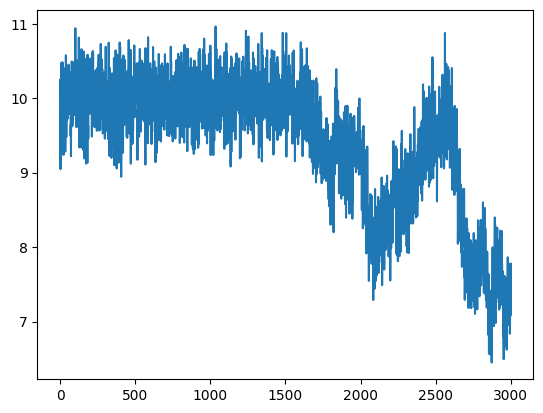

In [612]:
plt.plot(sat_trajectory.meas[:, 0])

## EKF

In [613]:
mu0 = np.array([10, 0, 0])
Sigma0 = np.eye(3)

In [614]:
t = 0

SAT_mu = np.zeros((N + 1, 3))
SAT_Sigma = np.zeros((N + 1, 3, 3))
SAT_resid = np.zeros((N + 1, 2))

SAT_mu[0] = mu0
SAT_Sigma[0] = Sigma0


meas_arr = sat_trajectory.meas
u_arr = sat_trajectory.u

for i in range(N):
    u_arr[i] = np.zeros(3)

    A = sat_jac_A(SAT_mu[i], dt, J)
    C = sat_jac_C(SAT_mu[i], max_c)

    mu_predict = sat_state_model(SAT_mu[i], u_arr[i], dt, J)
    Sigma_predict = A @ SAT_Sigma[i] @ A.T + Q

    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R)

    resid = meas_arr[i] - sat_measurement_model(SAT_mu[i], max_c)
    SAT_mu[i + 1] = mu_predict + K @ resid
    SAT_Sigma[i + 1] = Sigma_predict - K @ C @ Sigma_predict

    t += dt

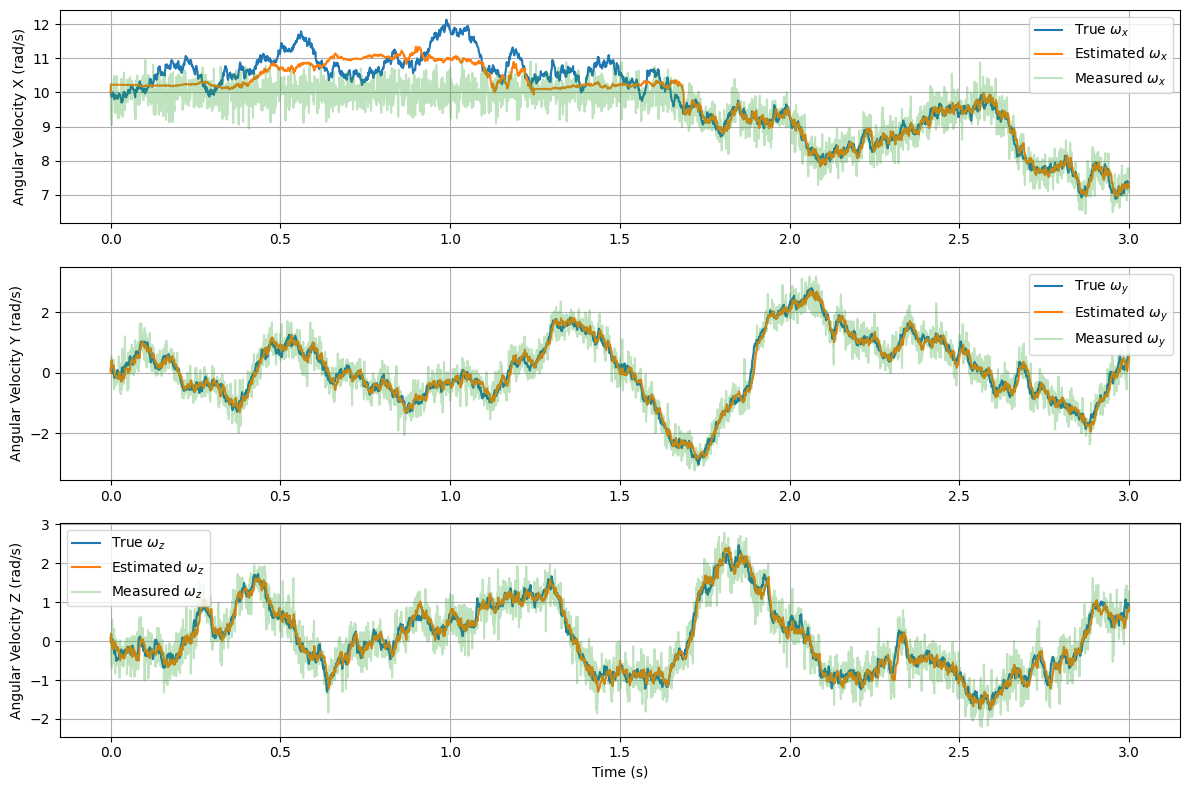

In [615]:
t = np.arange(N + 1) * dt

plt.figure(figsize=(12, 8))
plt.subplot(3, 1, 1)
plt.plot(t, sat_trajectory.X[:, 0], label=r"True $\omega_x$")
plt.plot(t, SAT_mu[:, 0], label=r"Estimated $\omega_x$")
plt.plot(t, meas_arr[:, 0], label=r"Measured $\omega_x$", alpha=0.3)
plt.ylabel("Angular Velocity X (rad/s)")
plt.grid()
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(t, sat_trajectory.X[:, 1], label=r"True $\omega_y$")
plt.plot(t, SAT_mu[:, 1], label=r"Estimated $\omega_y$")
plt.plot(t, meas_arr[:, 1], label=r"Measured $\omega_y$", alpha=0.3)
plt.ylabel("Angular Velocity Y (rad/s)")
plt.grid()
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(t, sat_trajectory.X[:, 2], label=r"True $\omega_z$")
plt.plot(t, SAT_mu[:, 2], label=r"Estimated $\omega_z$")
plt.plot(t, meas_arr[:, 2], label=r"Measured $\omega_z$", alpha=0.3)
plt.ylabel("Angular Velocity Z (rad/s)")
plt.grid()
plt.legend()
plt.xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Analysis

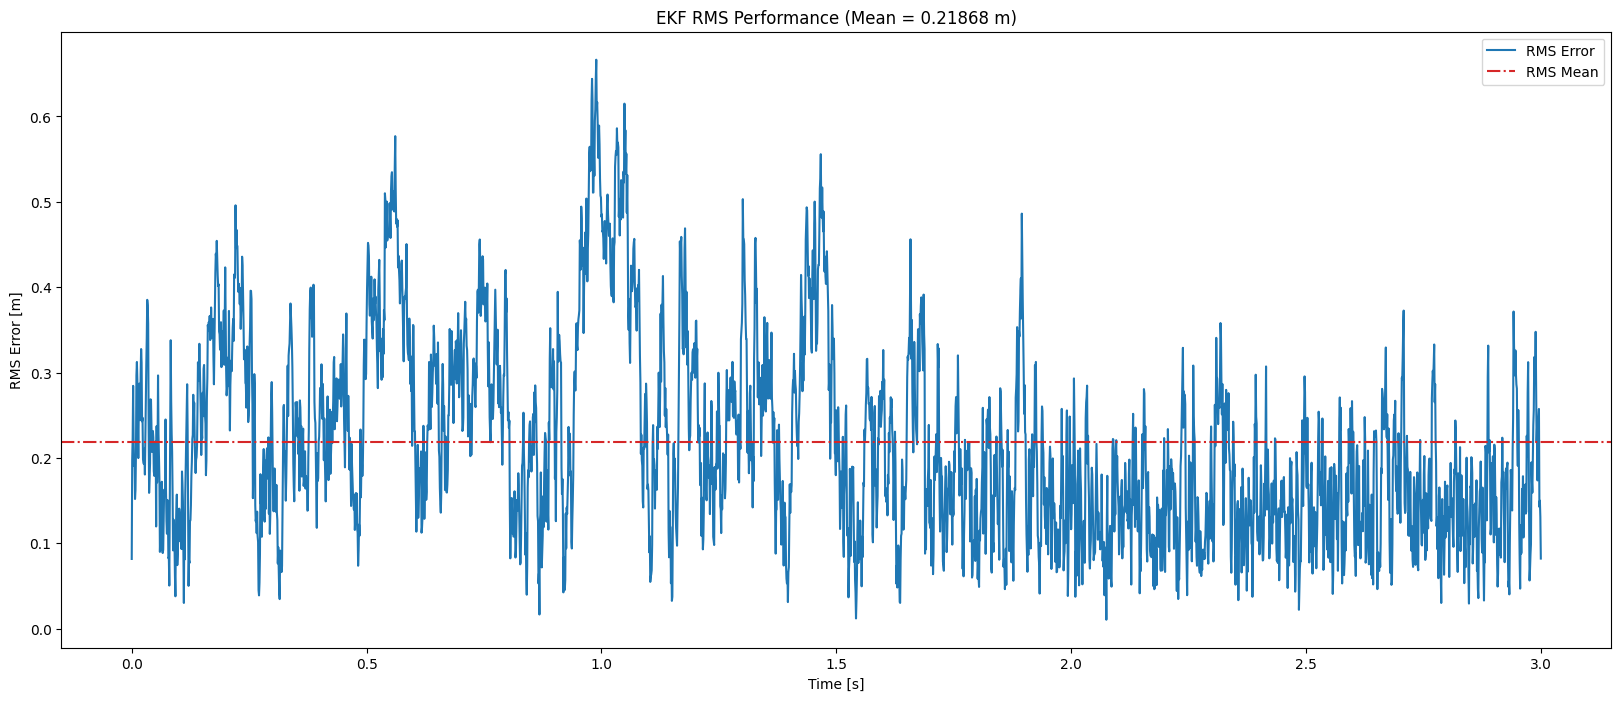

In [616]:
SAT_rms = np.array([rms(X - mu) for X, mu in zip(sat_trajectory.X, SAT_mu)])

plt.figure(figsize=(20, 8))
plt.plot(t, SAT_rms)
plt.xlabel("Time [s]")
plt.ylabel("RMS Error [m]")
plt.title(f"EKF RMS Performance (Mean = {np.mean(SAT_rms):.5f} m)")
plt.axhline(np.mean(SAT_rms), linestyle="-.", color="tab:red")
plt.legend(["RMS Error", "RMS Mean"])
plt.show()

# plt.plot(t, sat_trajectory.X[:, 0], label=r'True $\omega_x$')
# plt.plot(t, SAT_mu[:, 0], label=r'Estimated $\omega_x$')
# plt.show()

# Problem 4

## Defining system

In [617]:
# State: [px, py, theta]
# Input: [s, theta_dot]


def robot_state_model(X, u, dt):
    px, py, theta = X
    s, theta_dot = u

    px_next = px + dt * s * cos(theta)
    py_next = py + dt * s * sin(theta)
    theta_next = theta + dt * theta_dot

    return np.array([px_next, py_next, theta_next])


def robot_jac_A(X, u, dt):
    px, py, theta = X
    s, theta_dot = u

    return np.array(
        [[1, 0, -dt * s * sin(theta)], [0, 1, dt * s * cos(theta)], [0, 0, 1]]
    )

In [618]:
# State: [px, py, theta]
# Measurements: [y1, y2]


def robot_measurement_model(X):
    px, py, _ = X

    # Station locations
    x1, y1 = [30, -5]
    x2, y2 = [-10, 20]

    meas_1 = sqrt((px - x1) ** 2 + (py - y1) ** 2)
    meas_2 = sqrt((px - x2) ** 2 + (py - y2) ** 2)

    # return np.array([meas_1, meas_2]).reshape((2,1)) # Do I need to do this?
    return np.array([meas_1, meas_2])


def robot_jac_C(X, station_locations):
    px, py, _ = X

    x1, y1 = station_locations[0]  # [30, -5]
    x2, y2 = station_locations[1]  # [-10, 20]

    # Denominators are the same values as the measurements
    den1, den2 = robot_measurement_model(X)

    return np.array(
        [
            [(px - x1) / den1, (py - y1) / den1, 0],
            [(px - x2) / den2, (py - y2) / den2, 0],
        ]
    )

In [619]:
# Input as a function of time


def get_u(t):
    return np.array([1, sin(t)])

In [620]:
def robot_simulate(dt, N, X0, Q, R, seed=None):

    if seed is not None:
        np.random.seed(seed)

    ts = np.arange(N + 1) * dt

    meas_arr = np.zeros((N + 1, 2))
    u_arr = np.zeros((N + 1, 2))
    x_arr = np.zeros((N + 1, 3))

    x_arr[0] = X0
    meas_arr[0] = robot_measurement_model(X0)

    for i in range(N):
        t = ts[i]
        u_arr[i] = get_u(t)
        x_arr[i + 1] = robot_state_model(x_arr[i], u_arr[i], dt) + noise(Q)
        meas_arr[i + 1] = robot_measurement_model(x_arr[i]) + noise(R)

    return Trajectory(ts, x_arr, u_arr, meas_arr)

## Creating trajectory


In [621]:
dt = 0.5  # seconds
Q = 0.1 * dt * np.eye(3)
R = 0.1 * np.eye(2)
station_locations = np.array([[30, -5], [-10, 20]])

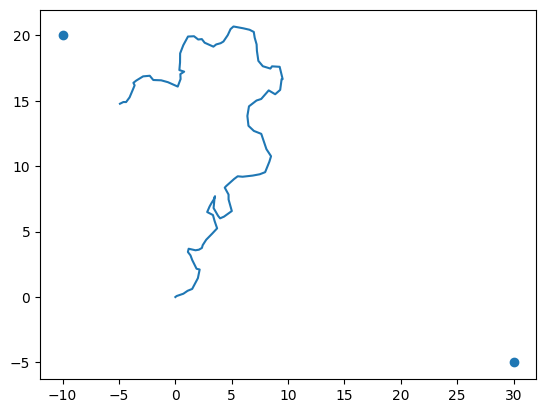

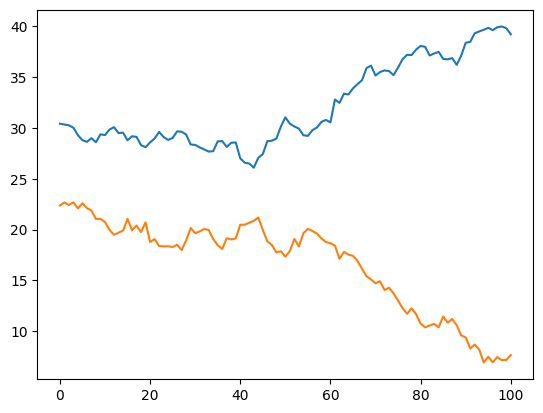

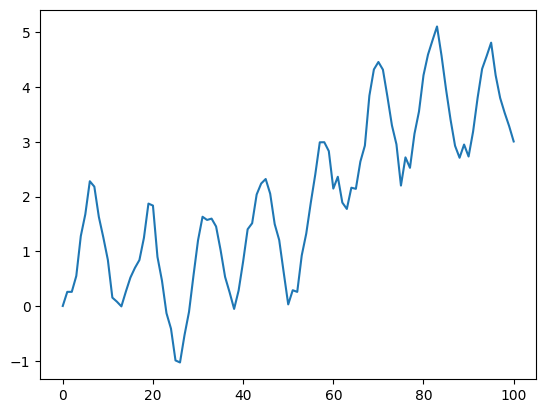

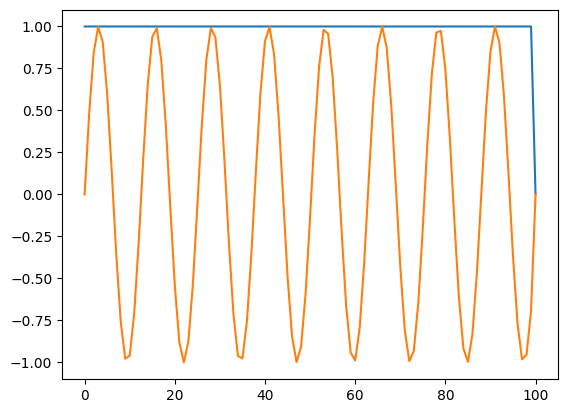

In [622]:
N = 100
X0 = np.array([0, 0, 0])
# trajectory = simulate(dt, N, X0, Q, R, 273)
trajectory = robot_simulate(dt, N, X0, Q, R, 100)
# trajectory = simulate(dt, N, X0, Q, R, 274)
# trajectory = simulate(dt, N, X0, np.zeros((3,3)), np.zeros((2,2)), 274)
# trajectory = simulate(dt, N, X0, Q, np.zeros((2,2)), 274)
# trajectory = simulate(dt, N, X0, np.zeros((3,3)), R, None)

plt.plot(trajectory.X[:, 0], trajectory.X[:, 1])
plt.scatter(station_locations[:, 0], station_locations[:, 1])
plt.show()
plt.plot(trajectory.meas)
plt.show()
plt.plot(trajectory.X[:, 2])
plt.show()
plt.plot(trajectory.u)
plt.show()

In [623]:
def observability(mu, u, ground_stations, dt):
    A = robot_jac_A(mu, u, dt)
    C = robot_jac_C(mu, ground_stations)

    N = A.shape[0]

    O = C
    for i in range(1, N):
        O = np.vstack((O, C @ np.linalg.matrix_power(A, i)))

    return O

## EKF

In [624]:
mu0 = np.zeros(3)
Sigma0 = 0.01 * np.eye(3)

In [625]:
t = 0

EKF_mu = np.zeros((N + 1, 3))
EKF_Sigma = np.zeros((N + 1, 3, 3))
EKF_resid = np.zeros((N + 1))

EKF_mu[0] = mu0
EKF_Sigma[0] = Sigma0


meas_arr = trajectory.meas
u_arr = trajectory.u
X_arr = trajectory.X

EKF_times = np.zeros(N)

for i in range(N):
    cur_time = time()

    u_arr[i] = get_u(t)

    # Check observability
    O = observability(EKF_mu[i], u_arr[i], station_locations, dt)
    if np.linalg.matrix_rank(O) < 3:
        print(f"Warning: System is not fully observable at {i}")

    A = robot_jac_A(EKF_mu[i], u_arr[i], dt)
    C = robot_jac_C(EKF_mu[i], station_locations)

    mu_predict = robot_state_model(EKF_mu[i], u_arr[i], dt)
    Sigma_predict = A @ EKF_Sigma[i] @ A.T + Q

    meas = robot_measurement_model(EKF_mu[i])
    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R)

    resid = meas_arr[i] - robot_measurement_model(EKF_mu[i])
    EKF_mu[i + 1] = mu_predict + K @ resid
    EKF_Sigma[i + 1] = Sigma_predict - K @ C @ Sigma_predict
    EKF_resid[i + 1] = norm(EKF_mu[i + 1][:2] - X_arr[i + 1][:2])  # Just position

    EKF_times[i] = time() - cur_time

    t += dt

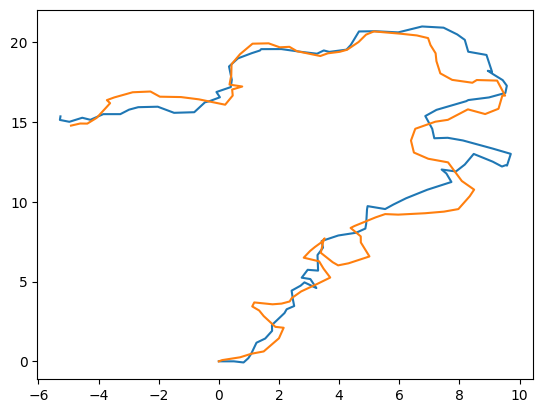

In [626]:
plt.plot(EKF_mu[:, 0], EKF_mu[:, 1])
plt.plot(trajectory.X[:, 0], trajectory.X[:, 1])

In [627]:
print(EKF_mu[-1])
print(EKF_Sigma[-1])
print(meas_arr[-1])

[-5.26491435 15.35255075  2.21046496]
[[ 0.22450161  0.25788354 -0.06485382]
 [ 0.25788354  0.37669647 -0.09712574]
 [-0.06485382 -0.09712574  0.23026537]]
[39.20659121  7.65704024]


## UKF

In [628]:
mu0 = np.zeros(3)
Sigma0 = 0.01 * np.eye(3)

In [629]:
def UT(mu, Sigma, l_param):
    """returns x and w (point arrays)"""

    n = len(mu)
    x = np.zeros((2 * n + 1, n))
    x[0] = mu

    factor = sqrt((l_param + n)) * cholesky(Sigma)
    for i in range(n):  # Gives 0 to n-1 though
        # Getting the column of the factor
        x[i + 1] = mu + factor[:, i]
        x[n + i + 1] = mu - factor[:, i]

    w = np.ones((2 * n + 1)) * 1 / 2 / (l_param + n)  # Since every one is the same
    w[0] = l_param / (l_param + n)

    return x, w

In [630]:
def UT_inv(X, W, Q):
    """Returns mu, sigma"""
    assert isinstance(X, np.ndarray)
    assert isinstance(W, np.ndarray)

    n = int((len(W) - 1) / 2)  # Crude lowkey

    w_column = W.reshape(len(W), 1)

    mu = np.sum(X * w_column, axis=0)  # Element-wise

    Sigma = np.zeros((n, n))
    for w_, x in zip(W, X):
        Sigma += w_ * np.outer((x - mu), (x - mu))

    return mu, Sigma + Q

In [631]:
t = 0

UKF_mu = np.zeros((N + 1, 3))
UKF_Sigma = np.zeros((N + 1, 3, 3))
UKF_resid = np.zeros((N + 1))

UKF_mu[0] = mu0
UKF_Sigma[0] = Sigma0

n = 3
m = 2

UKF_times = np.zeros(N)


X_arr = trajectory.X
meas_arr = trajectory.meas
u_arr = trajectory.u

for i in range(N):
    cur_time = time()

    u_arr[i] = get_u(t)

    # Check observability
    O = observability(UKF_mu[i], u_arr[i], station_locations, dt)
    if np.linalg.matrix_rank(O) < 3:
        print(f"Warning: System is not fully observable at {i}")

    # Predict
    X_predict, W_predict = UT(UKF_mu[i], UKF_Sigma[i], l_param=2)
    X_bar = np.array([robot_state_model(x, u_arr[i], dt) for x in X_predict])
    mu_predict, Sigma_predict = UT_inv(X_bar, W_predict, Q)

    # Update
    (
        X_predict,
        W_predict,
    ) = UT(mu_predict, Sigma_predict, l_param=2)
    y_predicted = np.array([robot_measurement_model(x) for x in X_predict])
    y_mean = sum(np.multiply(y_predicted.T, W_predict).T)

    # Sigma_y = np.zeros((m,m))
    Sigma_y = R.copy()
    for w, y in zip(W_predict, y_predicted):
        Sigma_y += w * (y - y_mean).reshape((m, 1)) @ (y - y_mean).reshape((1, m))
    # Sigma_y += R

    Sigma_xy = np.zeros((n, m))
    for w, x, y in zip(W_predict, X_predict, y_predicted):
        Sigma_xy += w * (x - mu_predict).reshape((n, 1)) @ (y - y_mean).reshape(1, m)

    # Gaussian Estimation Equations
    meas = meas_arr[i]
    UKF_mu[i + 1] = mu_predict + Sigma_xy @ inv(Sigma_y) @ (meas - y_mean)
    UKF_Sigma[i + 1] = Sigma_predict - Sigma_xy @ inv(Sigma_y) @ Sigma_xy.T
    UKF_resid[i + 1] = norm(UKF_mu[i + 1][:2] - X_arr[i + 1][:2])  # Just position

    UKF_times[i] = time() - cur_time

    t += dt

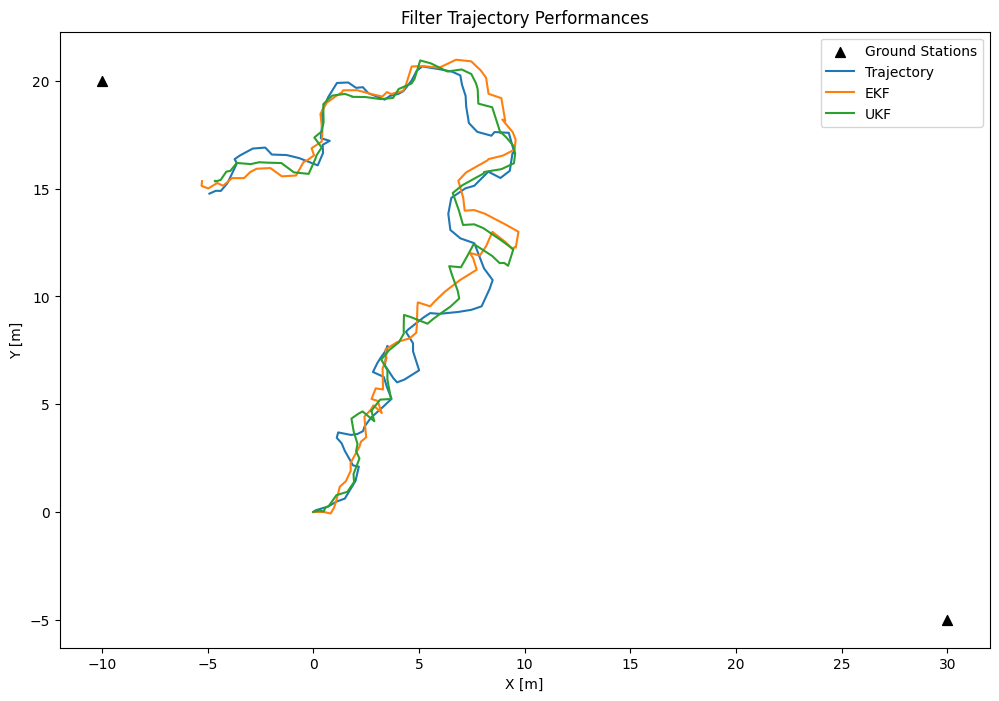

In [632]:
plt.figure(figsize=(12, 8))
plt.scatter(
    station_locations[:, 0],
    station_locations[:, 1],
    label="Ground Stations",
    marker="^",
    s=50,
    color="black",
)
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.plot(trajectory.X[:, 0], trajectory.X[:, 1], label="Trajectory")
plt.plot(EKF_mu[:, 0], EKF_mu[:, 1], label="EKF")
plt.plot(UKF_mu[:, 0], UKF_mu[:, 1], label="UKF")
plt.title("Filter Trajectory Performances")
plt.legend()
plt.show()

## Particle Filter

In [633]:
# Initial points
n_particles = 1000

particles = np.random.multivariate_normal(mu0, Sigma0, n_particles)

In [634]:
def pf_predict(particles, u, dt, Q):
    """Predicts with noise"""
    # new_particles = np.zeros_like(particles)
    # for i, particle in enumerate(particles):
    #     new_particles[i] = robot_state_model(particle, u, dt) + noise(Q)
    # return new_particles
    return np.array(
        [robot_state_model(particle, u, dt) + noise(Q) for particle in particles]
    )


def pf_weights(particles_predicted: np.ndarray, measurement: np.ndarray, R):
    weights = np.zeros((measurement.shape[0]))

    # for i in range(measurement.shape[0]):
    # weights[i] = 5
    expected_measurements = np.array(
        [robot_measurement_model(particle) for particle in particles_predicted]
    )
    R_inv = inv(R)
    # Gaussian (scaled) https://www.investopedia.com/terms/n/normaldistribution.asp
    # print(measurement)
    # print(expected_measurements[0])
    weights = np.array(
        [
            np.exp(-1 / 2 * ((measurement - meas).T @ R_inv @ (measurement - meas)))
            for meas in expected_measurements
        ]
    )

    return weights


# pf_update([4,5,6], np.array([3,0,3,4,5]))

In [635]:
t = 0

np.random.seed(1)

PF_mu = np.zeros((N + 1, 3))
PF_Sigma = np.zeros((N + 1, 3, 3))
PF_resid = np.zeros((N + 1))

PF_particles = np.zeros((N + 1, n_particles, 3))
# PF_weights = np.zeros((N+1, n_particles))

meas_arr = trajectory.meas
u_arr = trajectory.u
X_arr = trajectory.X


PF_mu[0] = mu0
PF_Sigma[0] = Sigma0
PF_resid[0] = norm(mu0 - X_arr[0])

PF_times = np.zeros(N)

PF_particles[0] = particles
# PF_weights[0] = np.ones(n_particles)/n_particles

for i in range(N):
    cur_time = time()

    u_arr[i] = get_u(t)

    # Check observability
    O = observability(PF_mu[i], u_arr[i], station_locations, dt)
    if np.linalg.matrix_rank(O) < 3:
        print(f"Warning: System is not fully observable at {i}")

    # Predict
    p_pred = pf_predict(PF_particles[i], u_arr[i], dt, Q)
    weights = pf_weights(p_pred, meas_arr[i + 1], R)

    weights += 1e-300  # Avoid dividing by 0 (thanks matthias)
    weights /= np.sum(weights)

    idx = np.random.choice(n_particles, size=n_particles, p=weights)
    p_update = p_pred[idx]

    PF_particles[i + 1] = p_update

    mu = np.mean(p_update, axis=0)
    PF_mu[i + 1] = mu
    PF_Sigma[i + 1] = np.cov(p_update.T)
    PF_resid[i + 1] = norm(PF_mu[i + 1][:2] - X_arr[i + 1][:2])  # Just position

    PF_times[i] = time() - cur_time

    t += dt

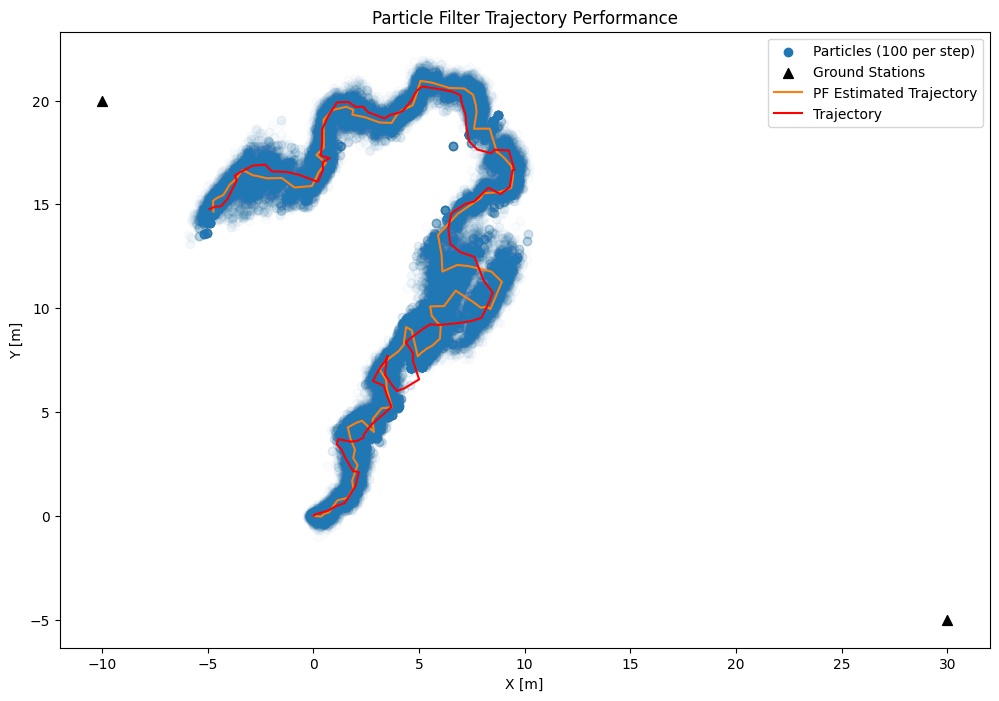

In [636]:
plt.figure(figsize=(12, 8))
plt.scatter(
    PF_particles[:, :, 0].flatten(),
    PF_particles[:, :, 1].flatten(),
    alpha=0.02,
    color="tab:blue",
)
plt.scatter(
    [PF_particles[:, :, 0].flatten()[0]],
    [PF_particles[:, :, 1].flatten()[0]],
    label=f"Particles ({N} per step)",
    color="tab:blue",
)
plt.scatter(
    station_locations[:, 0],
    station_locations[:, 1],
    label="Ground Stations",
    marker="^",
    s=50,
    color="black",
)
plt.plot(PF_mu[:, 0], PF_mu[:, 1], color="tab:orange", label="PF Estimated Trajectory")
plt.plot(trajectory.X[:, 0], trajectory.X[:, 1], color="red", label="Trajectory")
plt.title("Particle Filter Trajectory Performance")
plt.legend()
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.show()

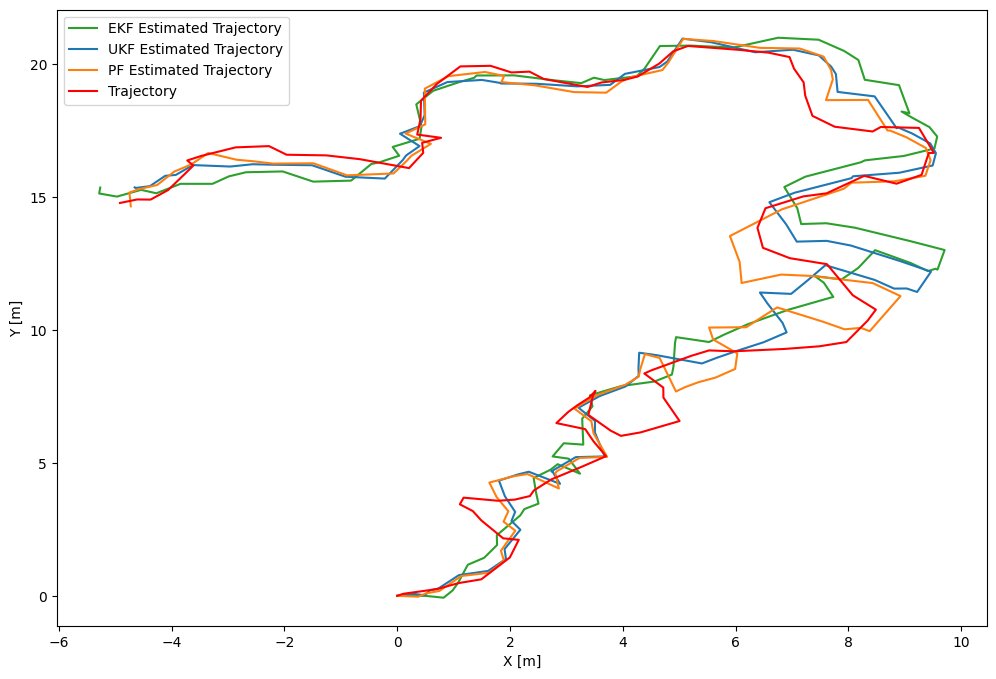

In [637]:
plt.figure(figsize=(12, 8))
plt.plot(
    EKF_mu[:, 0], EKF_mu[:, 1], color="tab:green", label="EKF Estimated Trajectory"
)
plt.plot(UKF_mu[:, 0], UKF_mu[:, 1], color="tab:blue", label="UKF Estimated Trajectory")
plt.plot(PF_mu[:, 0], PF_mu[:, 1], color="tab:orange", label="PF Estimated Trajectory")
plt.plot(trajectory.X[:, 0], trajectory.X[:, 1], color="red", label="Trajectory")
plt.legend()
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.show()

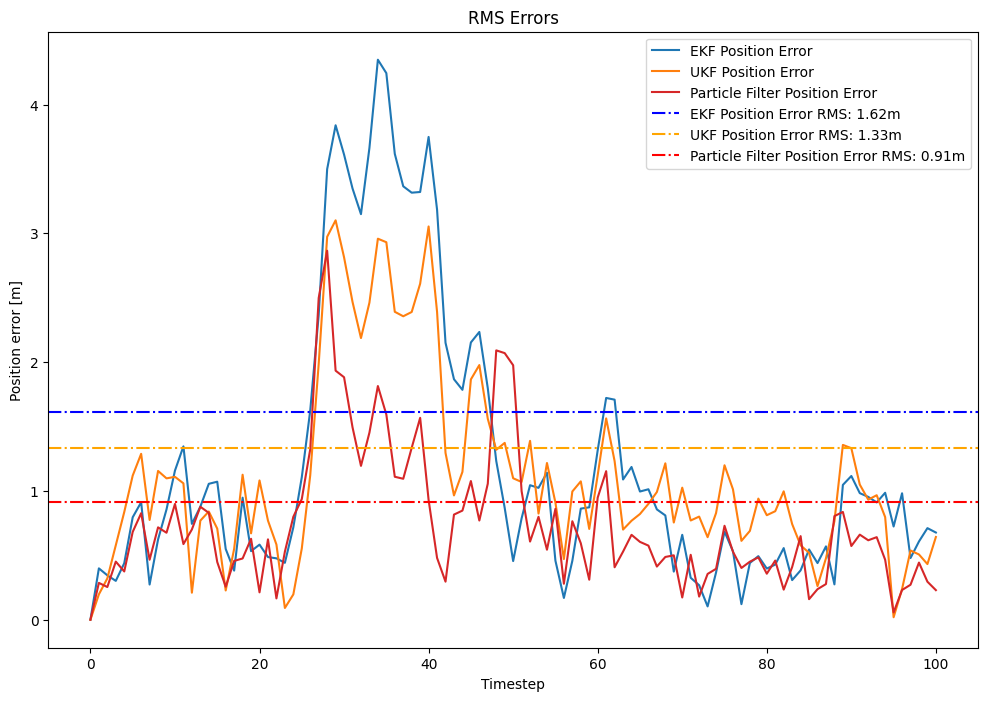

In [638]:
plt.figure(figsize=(12, 8))
plt.plot(EKF_resid, color="tab:blue", label="EKF Position Error")
plt.plot(UKF_resid, color="tab:orange", label="UKF Position Error")
plt.plot(PF_resid, color="tab:red", label="Particle Filter Position Error")

plt.axhline(
    rms(EKF_resid),
    linestyle="-.",
    color="blue",
    label=f"EKF Position Error RMS: {rms(EKF_resid):.2f}m",
)
plt.axhline(
    rms(UKF_resid),
    linestyle="-.",
    color="orange",
    label=f"UKF Position Error RMS: {rms(UKF_resid):.2f}m",
)
plt.axhline(
    rms(PF_resid),
    linestyle="-.",
    color="red",
    label=f"Particle Filter Position Error RMS: {rms(PF_resid):.2f}m",
)

plt.title("RMS Errors")
plt.xlabel("Timestep")
plt.ylabel("Position error [m]")
plt.legend()
plt.show()

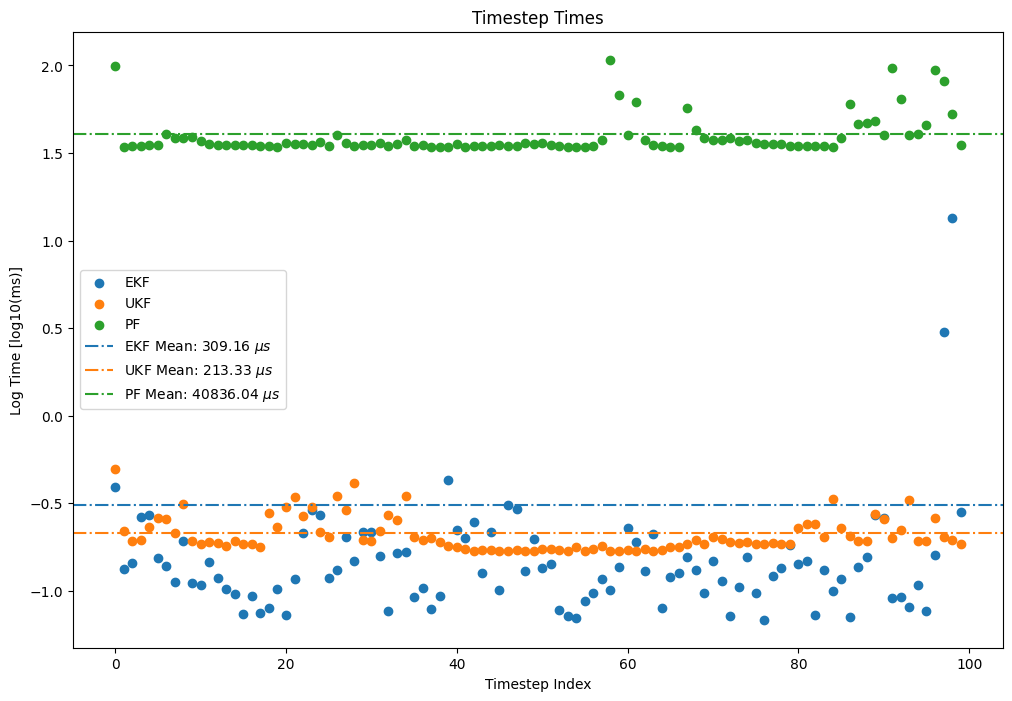

In [639]:
plt.figure(figsize=(12, 8))
idx_arr = np.arange(N)
plt.scatter(idx_arr, np.log10(EKF_times * 1000), label="EKF")
plt.scatter(idx_arr, np.log10(UKF_times * 1000), label="UKF")
plt.scatter(idx_arr, np.log10(PF_times * 1000), label="PF")

plt.axhline(
    np.log10(np.mean(EKF_times * 1000)),
    linestyle="-.",
    color="tab:blue",
    label=f"EKF Mean: {np.mean(EKF_times) * 1e6:.2f} " r"$\mu s$",
)
plt.axhline(
    np.log10(np.mean(UKF_times * 1000)),
    linestyle="-.",
    color="tab:orange",
    label=f"UKF Mean: {np.mean(UKF_times) * 1e6:.2f} " r"$\mu s$",
)
plt.axhline(
    np.log10(np.mean(PF_times * 1000)),
    linestyle="-.",
    color="tab:green",
    label=f"PF Mean: {np.mean(PF_times) * 1e6:.2f} " r"$\mu s$",
)

plt.ylabel("Log Time [log10(ms)]")
plt.xlabel("Timestep Index")
plt.title("Timestep Times")
plt.legend()
plt.show()

In [640]:
def get_ellipse_points(mu: np.ndarray, Sigma: np.ndarray, P=0.95, N=200):
    t = np.linspace(0, 2 * np.pi, N)
    circle = np.vstack((np.cos(t), np.sin(t)))
    rhs = -2 * np.log(1 - P)
    ellipse = np.sqrt(rhs) * circle
    scaled_ellipse = sqrtm(Sigma) @ ellipse  # circle -> ellipse
    return scaled_ellipse + mu.reshape(2, 1)

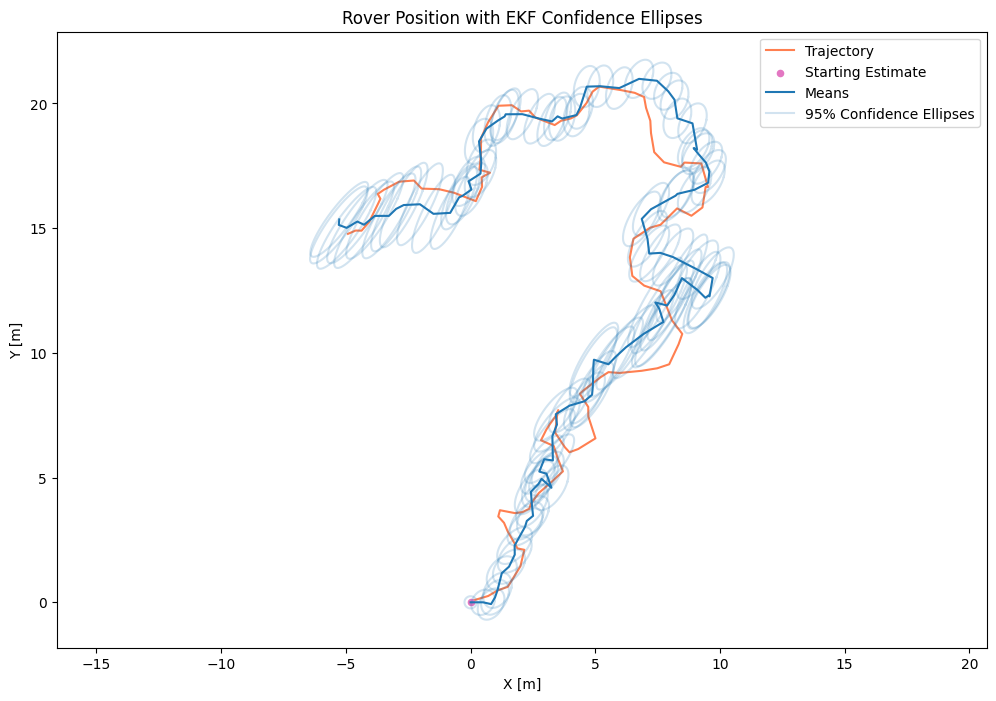

In [641]:
plt.figure(figsize=(12, 8))
plt.axis("equal")
plt.plot(X_arr[:, 0], X_arr[:, 1], color="coral", zorder=1)
# plt.scatter([x0[0,1]], [x0[0,1]], color="tab:red", label="Starting Position", s=40, marker="o")
plt.scatter([EKF_mu[0, 0]], [EKF_mu[0, 1]], color="tab:pink", s=20, marker="o")

plt.plot(EKF_mu[:, 0], EKF_mu[:, 1], color="tab:blue")

for mu, sigma in zip(EKF_mu, EKF_Sigma):
    mu = mu[0:2]
    sigma = sigma[0:2, 0:2]
    plt.plot(*get_ellipse_points(mu, sigma), color="tab:blue", alpha=0.2)


plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("Rover Position with EKF Confidence Ellipses")
plt.legend(("Trajectory", "Starting Estimate", "Means", "95% Confidence Ellipses"))
plt.show()

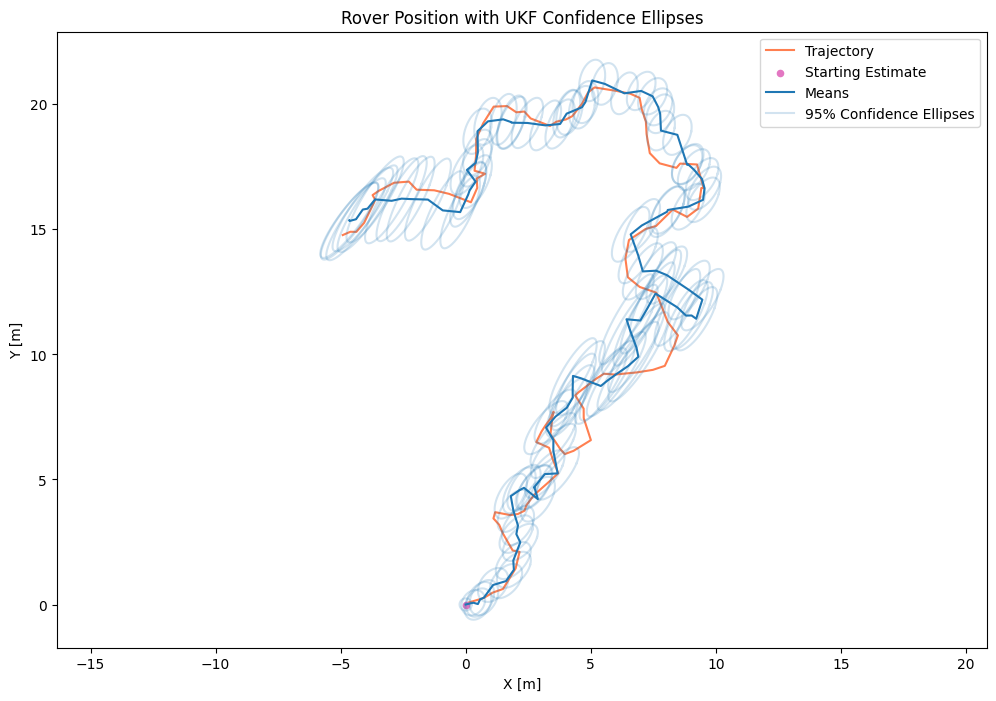

In [642]:
plt.figure(figsize=(12, 8))
plt.axis("equal")
plt.plot(X_arr[:, 0], X_arr[:, 1], color="coral", zorder=1)
# plt.scatter([x0[0,1]], [x0[0,1]], color="tab:red", label="Starting Position", s=40, marker="o")
plt.scatter([UKF_mu[0, 0]], [UKF_mu[0, 1]], color="tab:pink", s=20, marker="o")

plt.plot(UKF_mu[:, 0], UKF_mu[:, 1], color="tab:blue")

for mu, sigma in zip(UKF_mu, EKF_Sigma):
    mu = mu[0:2]
    sigma = sigma[0:2, 0:2]
    plt.plot(*get_ellipse_points(mu, sigma), color="tab:blue", alpha=0.2)


plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("Rover Position with UKF Confidence Ellipses")
plt.legend(("Trajectory", "Starting Estimate", "Means", "95% Confidence Ellipses"))
plt.show()

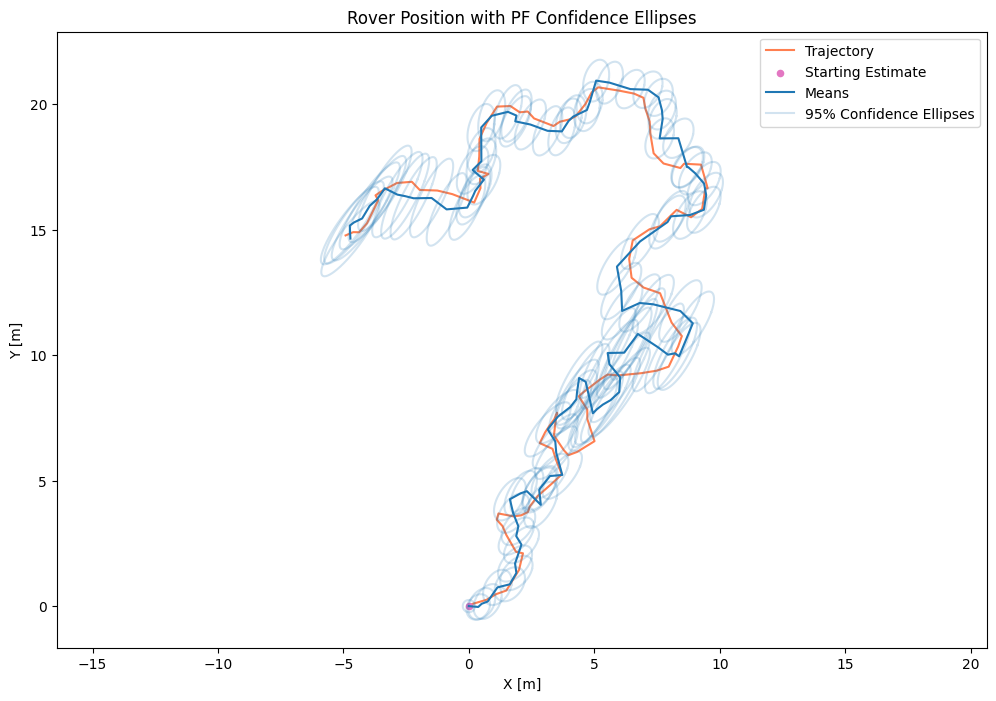

In [643]:
plt.figure(figsize=(12, 8))
plt.axis("equal")
plt.plot(X_arr[:, 0], X_arr[:, 1], color="coral", zorder=1)
# plt.scatter([x0[0,1]], [x0[0,1]], color="tab:red", label="Starting Position", s=40, marker="o")
plt.scatter([PF_mu[0, 0]], [PF_mu[0, 1]], color="tab:pink", s=20, marker="o")

plt.plot(PF_mu[:, 0], PF_mu[:, 1], color="tab:blue")

for mu, sigma in zip(PF_mu, EKF_Sigma):
    mu = mu[0:2]
    sigma = sigma[0:2, 0:2]
    plt.plot(*get_ellipse_points(mu, sigma), color="tab:blue", alpha=0.2)


plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("Rover Position with PF Confidence Ellipses")
plt.legend(("Trajectory", "Starting Estimate", "Means", "95% Confidence Ellipses"))
plt.show()